# Portfolio Allocation Project — Part 2: Minimum-Variance Portfolio

**Goal:** estimate $\Sigma$ from an estimation period, compute the minimum-variance weights

$$\hat{\mathbf a} = \frac{\hat\Sigma^{-1}\boldsymbol\iota}{\boldsymbol\iota^\top\hat\Sigma^{-1}\boldsymbol\iota}$$

and check how they perform on a test period they never saw, compared with equal weights (1/N).

**Structure:** sections 1–3 prepare the data and estimate $\hat\Sigma$; sections 4–6 compute the weights and compare them in-sample; sections 7–8 test them out of sample in 2025; section 9 repeats the test for 2020 and 2022; section 10 summarizes the conclusions.

**Input:** `returns.csv` from Part 1 (daily log returns, one column per asset).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRADING_DAYS = 252

## 1. Load the returns

The columns keep the same order as in Part 1. That order defines which position in $\mathbf a$ and $\Sigma$ belongs to which asset.

In [2]:
returns = pd.read_csv("returns.csv", index_col=0, parse_dates=True)
tickers = list(returns.columns)
K = len(tickers)
print(f"{returns.shape[0]} days x {K} assets: {tickers}")

2721 days x 10 assets: ['SPY', 'IWM', 'EFA', 'EEM', 'TLT', 'IEF', 'LQD', 'EMLC', 'GLD', 'VNQ']


## 2. Split into estimation and test periods

The weights are computed **only** from the estimation period. The test period plays the role of "the future."

We use 4 years of estimation (2021–2024) and 1 year of test (2025). Section 9 repeats the exercise with 2020 and 2022 as test years, and Part 3 will replace this single split with a rolling window.

In [3]:
EST_START, EST_END = "2021-01-01", "2024-12-31"
TEST_START, TEST_END = "2025-01-01", "2025-12-31"

est = returns.loc[EST_START:EST_END]
test = returns.loc[TEST_START:TEST_END]

print(f"Estimation: {est.index[0].date()} to {est.index[-1].date()}  ({len(est)} days)")
print(f"Test:       {test.index[0].date()} to {test.index[-1].date()}  ({len(test)} days)")

Estimation: 2021-01-04 to 2024-12-31  (1005 days)
Test:       2025-01-02 to 2025-12-31  (250 days)


## 3. Estimate $\hat\Sigma$

$\hat\Sigma$ is the sample covariance matrix of the daily returns in the estimation period: a $K \times K$ matrix with variances on the diagonal and covariances off it. We keep it as a numpy array for the linear algebra.

In [4]:
Sigma_hat = est.cov().to_numpy()

print("Annualized volatility per asset (estimation period):")
print(pd.Series(np.sqrt(np.diag(Sigma_hat) * TRADING_DAYS), index=tickers).round(3))

Annualized volatility per asset (estimation period):
SPY     0.165
IWM     0.229
EFA     0.159
EEM     0.184
TLT     0.169
IEF     0.081
LQD     0.092
EMLC    0.098
GLD     0.144
VNQ     0.193
dtype: float64


## 4. The minimum-variance weights

The formula is written as a function so it can be reused with any $\Sigma$ (in Part 3, the rolling window will call it once per month):

1. Solve $\Sigma\mathbf x = \boldsymbol\iota$ for $\mathbf x = \Sigma^{-1}\boldsymbol\iota$. We use `np.linalg.solve` instead of inverting $\Sigma$: it's faster and numerically safer.
2. Divide $\mathbf x$ by $\boldsymbol\iota^\top\mathbf x$ (the sum of its entries), so the weights add up to 1.

In [5]:
def min_variance_weights(Sigma):
    """Minimum-variance weights (shorting allowed) for a covariance matrix Sigma."""
    iota = np.ones(Sigma.shape[0])
    x = np.linalg.solve(Sigma, iota)
    a = x / x.sum()
    return a

## 5. Weights for our assets, and the 1/N benchmark

The equal-weight portfolio (1/N) puts the same amount in every asset. It needs no estimation at all, which makes it the natural benchmark: if the optimized portfolio can't beat it out of sample, the optimization isn't adding value.

In [6]:
a_mv = min_variance_weights(Sigma_hat)
a_ew = np.ones(K) / K

print(f"Total short position: {-a_mv[a_mv < 0].sum():.1%}")
weights = pd.DataFrame({"min_variance": a_mv, "equal_weight": a_ew}, index=tickers)
weights.round(3)

Total short position: 73.1%


,min_variance,equal_weight
SPY,0.090,0.1
IWM,-0.032,0.1
EFA,-0.042,0.1
EEM,0.012,0.1
TLT,-0.577,0.1
IEF,1.245,0.1
LQD,0.258,0.1
EMLC,0.127,0.1
GLD,-0.034,0.1
VNQ,-0.046,0.1


**Reading the weights**

- **The largest weight is IEF (124.5%)**, the lowest-volatility asset (8.1%). But its weight is above 100%, so low volatility is not the whole story: the extra exposure is financed by a **short position in TLT (−57.7%)**.
- **This is the hedge example applied to Treasuries.** IEF and TLT are both U.S. Treasury ETFs, so they are highly correlated, and TLT is about twice as volatile (16.9% vs 8.1%). High correlation plus different volatilities is exactly where the formula goes long the calm asset and short the volatile one: the short TLT position cancels much of IEF's interest-rate risk.
- **LQD (25.8%) and EMLC (12.7%)** add diversification, while IWM, EFA, GLD and VNQ get small short positions (−3% to −5%).
- **The total short position is 73.1% of capital**, so gross exposure is about 246%. That is leverage, and a broker charges for it (see the borrowing cost below).

## 6. In-sample comparison

Portfolio variance is $\mathbf a^\top\Sigma\mathbf a$. In the estimation period, the minimum-variance portfolio has to win (or tie), since that is what it was built to do.

In [7]:
def portfolio_volatility(a, Sigma):
    """Annualized volatility of a portfolio with weights a, from a daily covariance matrix."""
    var_daily = a @ Sigma @ a
    ann_vol = np.sqrt(var_daily) * np.sqrt(TRADING_DAYS)
    return ann_vol

for name, a in [("min_variance", a_mv), ("equal_weight", a_ew)]:
    print(f"{name:>14}: in-sample volatility = {portfolio_volatility(a, Sigma_hat):.2%}")

  min_variance: in-sample volatility = 5.28%
  equal_weight: in-sample volatility = 10.70%


In-sample, minimum variance **halves** the volatility of 1/N (5.28% vs 10.70%), and it is even lower than IEF on its own. This number is optimistic by construction: the weights were fitted to exactly this data, including its estimation noise. The real test is out of sample.

## 7. Out-of-sample test

We apply the **same fixed weights** to every day of the test period. This is $R\mathbf a$: the data matrix times the weights gives one portfolio return per day.

Metrics for each strategy (annualized):
- **Realized volatility**: the main score, since this is what minimum variance promises to keep low.
- **Mean return**
- **Return / volatility ratio** (a simple Sharpe ratio, ignoring the risk-free rate)
- **Maximum drawdown**: the worst peak-to-bottom fall in portfolio value.

*Simplification:* holding fixed weights for a full year assumes you rebalance back to them every day. Part 3 will rebalance monthly.

In [8]:
def performance(port_returns):
    """Annualized metrics for a Series of daily portfolio log returns."""
    ann_mean_return = port_returns.mean() * TRADING_DAYS
    ann_volatility = port_returns.std() * np.sqrt(TRADING_DAYS)
    return_over_vol = ann_mean_return / ann_volatility
    value = np.exp(port_returns.cumsum())
    drawdown = value / value.cummax() - 1
    max_drawdown = np.min(drawdown)
    return pd.Series({
        "ann_return": ann_mean_return,
        "ann_volatility": ann_volatility,
        "return_over_vol": return_over_vol,
        "max_drawdown": max_drawdown,
    })


port_test = pd.DataFrame({
    "min_variance": test @ a_mv,
    "equal_weight": test @ a_ew,
})
pd.DataFrame({name: performance(port_test[name]) for name in port_test}).round(4)

,min_variance,equal_weight
ann_return,0.0988,0.1755
ann_volatility,0.0348,0.0995
return_over_vol,2.8370,1.7637
max_drawdown,-0.0117,-0.0815


**Results for 2025**

- **Volatility:** minimum variance kept its advantage out of sample: 3.48% vs 9.95% for 1/N, about a third of the risk.
- **Out-of-sample volatility was *lower* than in-sample (3.48% vs 5.28%).** This is unusual: normally the out-of-sample number is higher, because the weights are fitted to estimation noise. The likely reason is that 2025 was a calmer year than 2021–2024, which included the 2022 rate shock. 1/N also became less volatile (10.70% → 9.95%), which supports this explanation. Section 9 checks whether this holds in other years.
- **Return:** 1/N earned more (17.55% vs 9.88%), as expected in a strong year for equities. Minimum variance makes no promise about returns, but it was more efficient per unit of risk (return/vol of 2.84 vs 1.76).
- **Drawdown:** the worst fall was −1.17% for minimum variance vs −8.15% for 1/N.

### Borrowing cost of the short positions

With an annual borrow fee $c$, we subtract $\frac{c}{252}\sum_{a_k<0}|a_k|$ from each daily return. It doesn't change the volatility (subtracting a constant never does), but it does lower the return.

In [9]:
BORROW_FEE = 0.005   # 0.5% per year

short_exposure = -a_mv[a_mv < 0].sum()
daily_cost = BORROW_FEE / TRADING_DAYS * short_exposure
port_test["min_variance_net"] = port_test["min_variance"] - daily_cost

print(f"Total short position: {short_exposure:.1%}")
for fee in [0.0025, 0.005, 0.01, 0.03]:
    print(f"  borrow fee {fee:.2%} per year -> annual cost {short_exposure * fee:.2%}")

pd.DataFrame({name: performance(port_test[name]) for name in port_test}).round(4)

Total short position: 73.1%
  borrow fee 0.25% per year -> annual cost 0.18%
  borrow fee 0.50% per year -> annual cost 0.37%
  borrow fee 1.00% per year -> annual cost 0.73%
  borrow fee 3.00% per year -> annual cost 2.19%


,min_variance,equal_weight,min_variance_net
ann_return,0.0988,0.1755,0.0951
ann_volatility,0.0348,0.0995,0.0348
return_over_vol,2.8370,1.7637,2.7320
max_drawdown,-0.0117,-0.0815,-0.0118


With a 73.1% short position, a 0.5% borrow fee costs about **0.37% per year**, lowering the return from 9.88% to 9.51%. Treasury ETFs are usually cheap to borrow, so this is a reasonable base case. Even at a 3% fee (about 2.2% per year), minimum variance would keep its volatility advantage, but its return/volatility ratio would fall noticeably.

## 8. Growth of $1 in the test period

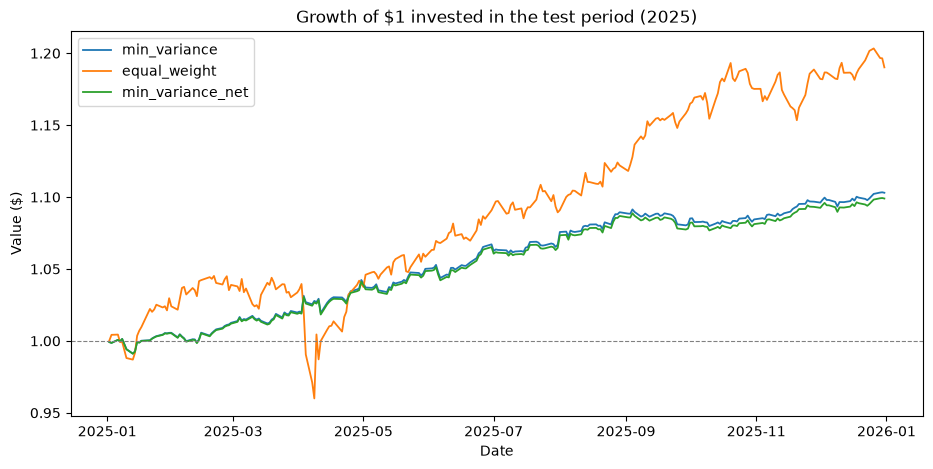

In [10]:
growth = np.exp(port_test.cumsum())

fig, ax = plt.subplots(figsize=(11, 5))
for name in growth.columns:
    ax.plot(growth.index, growth[name], label=name, linewidth=1.3)
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_title(f"Growth of $1 invested in the test period ({TEST_START[:4]})")
ax.set_xlabel("Date")
ax.set_ylabel("Value ($)")
ax.legend()
plt.show()

The chart shows the trade-off clearly: 1/N ends the year higher but with a much bumpier path, including a sharp fall during the spring sell-off, while minimum variance grows slowly and steadily. The borrow fee barely separates the net and gross minimum-variance lines.

## 9. Robustness: other test years

A single test year can be misleading. We repeat the whole exercise for **2020** (COVID crash) and **2022** (inflation and rate shock), each time re-estimating $\hat\Sigma$ on the 4 previous years.

In [11]:
def evaluate_test_year(year, n_est_years=4):
    """Estimate on the n_est_years before `year`, test on `year`."""
    est_y = returns.loc[f"{year - n_est_years}-01-01":f"{year - 1}-12-31"]
    test_y = returns.loc[f"{year}-01-01":f"{year}-12-31"]

    Sigma_y = est_y.cov().to_numpy()
    a = min_variance_weights(Sigma_y)
    mv = performance(test_y @ a)
    ew = performance(test_y @ a_ew)

    return pd.Series({
        "mv_in_sample_vol": portfolio_volatility(a, Sigma_y),
        "mv_test_vol": mv["ann_volatility"],
        "ew_test_vol": ew["ann_volatility"],
        "mv_test_return": mv["ann_return"],
        "ew_test_return": ew["ann_return"],
        "mv_max_drawdown": mv["max_drawdown"],
        "ew_max_drawdown": ew["max_drawdown"],
        "mv_total_short": -a[a < 0].sum(),
    })


robustness = pd.DataFrame({year: evaluate_test_year(year) for year in [2020, 2022, 2025]}).T
robustness.round(4)

,mv_in_sample_vol,mv_test_vol,ew_test_vol,mv_test_return,ew_test_return,mv_max_drawdown,ew_max_drawdown,mv_total_short
2020,0.0229,0.0621,0.1897,0.0685,0.1148,-0.0751,-0.2206,0.5737
2022,0.0284,0.0764,0.1455,-0.0847,-0.1982,-0.1136,-0.2379,0.4776
2025,0.0528,0.0348,0.0995,0.0988,0.1755,-0.0117,-0.0815,0.7314


The table summarizes each year in a few numbers. The charts below show the full path of $1 invested in each strategy, with all three panels on the same vertical scale so the size of the falls can be compared directly.

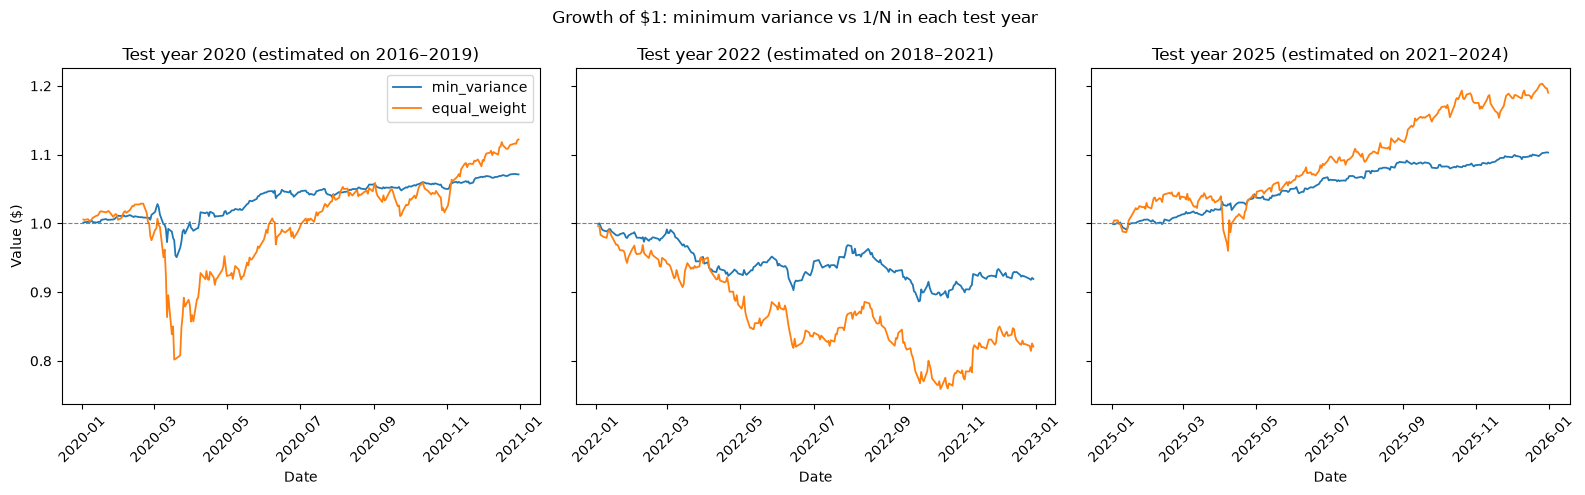

In [12]:
test_years = [2020, 2022, 2025]

fig, axes = plt.subplots(1, len(test_years), figsize=(16, 5), sharey=True)

for ax, year in zip(axes, test_years):
    est_y = returns.loc[f"{year - 4}-01-01":f"{year - 1}-12-31"]
    test_y = returns.loc[f"{year}-01-01":f"{year}-12-31"]

    a = min_variance_weights(est_y.cov().to_numpy())
    growth_y = np.exp(pd.DataFrame({
        "min_variance": test_y @ a,
        "equal_weight": test_y @ a_ew,
    }).cumsum())

    for name in growth_y.columns:
        ax.plot(growth_y.index, growth_y[name], label=name, linewidth=1.3)
    ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
    ax.set_title(f"Test year {year} (estimated on {year - 4}–{year - 1})")
    ax.set_xlabel("Date")
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("Value ($)")
axes[0].legend()
fig.suptitle("Growth of $1: minimum variance vs 1/N in each test year")
plt.tight_layout()
plt.show()

Across the three test years, minimum variance follows a much smoother path than 1/N. The difference is largest in the stress years: in 2020 it avoided most of the COVID crash (worst fall of −7.5% vs −22.1% for 1/N), and in 2022 it lost less than half as much as 1/N (−8.5% vs −19.8%). In strong equity years such as 2020's recovery and 2025, the price of that stability is a lower final value.

**What changes and what doesn't**

- **Volatility ranking is stable:** minimum variance had lower volatility than 1/N in all three years (6.2% vs 19.0% in 2020, 7.6% vs 14.6% in 2022, 3.5% vs 10.0% in 2025).
- **In-sample volatility is usually too optimistic.** In 2020 and 2022, the realized volatility was about **2.7 times** the in-sample estimate (2.3% → 6.2% and 2.8% → 7.6%). 2025 is the exception, not the rule.
- **Drawdowns were always smaller** for minimum variance (−7.5% vs −22.1% in 2020, −11.4% vs −23.8% in 2022).
- **The return ranking depends on the year.** 1/N earned more in 2020 and 2025, while in 2022 both lost money but minimum variance lost much less (−8.5% vs −19.8%).
- **The structure of the weights is similar every year:** long IEF (115%–138%) and short TLT (−39% to −58%), with total short positions between 48% and 73%.

## 10. Conclusions

1. **Volatility.** Minimum variance delivered lower out-of-sample volatility than 1/N in every test year: about 65% lower in 2025, 67% lower in 2020 and 47% lower in 2022. Compared with in-sample, the 2025 result (3.48% vs 5.28%) was unusually favorable; in 2020 and 2022 the realized volatility was about 2.7 times the in-sample estimate. In-sample volatility should be read as a lower bound, not a forecast.

2. **Returns.** Minimum variance makes no promise about returns, and 1/N earned more in the strong equity years (2020 and 2025). Minimum variance earned more per unit of risk in 2025 (return/vol 2.84 vs 1.76) and protected capital in 2022, when stocks and bonds fell together (−8.5% vs −19.8%).

3. **Relying on one test year.** The volatility and drawdown rankings held in 2020, 2022 and 2025, but the size of the gap, the in-sample vs out-of-sample relationship and the return ranking all changed from year to year. Judging the strategy on 2025 alone would have overstated its out-of-sample precision. This motivates Part 3: a rolling-window backtest with monthly rebalancing, which evaluates the strategy over many periods instead of one.

4. **Short positions and costs.** The portfolio is heavily long-short: in 2025 it held 124.5% in IEF financed largely by a −57.7% position in TLT, for a total short of 73.1% (gross exposure of about 246%). At a 0.5% borrow fee this costs about 0.37% per year, and about 2.2% at a 3% fee. Beyond the fee, the strategy depends on the IEF–TLT relationship staying stable and requires margin. A **long-only** version (no short sales) is a natural next step to compare.